# 03 — Feature Engineering & Selection

Target: log(salary ÷ cap) in season *t*, predicted only from information known **before** season *t*.

In [1]:
import sys
sys.path.append("../src")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import build_features
import plotting as P

P.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.0f}" if abs(x) >= 1000 else f"{x:,.3f}")

import warnings
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LassoCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = build_features(pd.read_csv("../data/processed/player_seasons.csv"))

## 1. Engineered features (`src/features.py`)

| Feature | Why |
|---|---|
| previous-season stats (`prev_*`) | contracts are priced on past seasons |
| 2-season averages (`avg2_*`) | smooths one-off seasons |
| shrunk rate stats (PER, BPM, TS%, …) | a 20-minute season is noise; pulled toward league average |
| per-36 stats, availability, start rate | rate, durability, role |
| All-Star / All-NBA | reputation |
| age, experience, draft pick, undrafted | career stage and pedigree |
| position dummies, shortened-season flag | controls |

## 2. Minimum-minutes filter

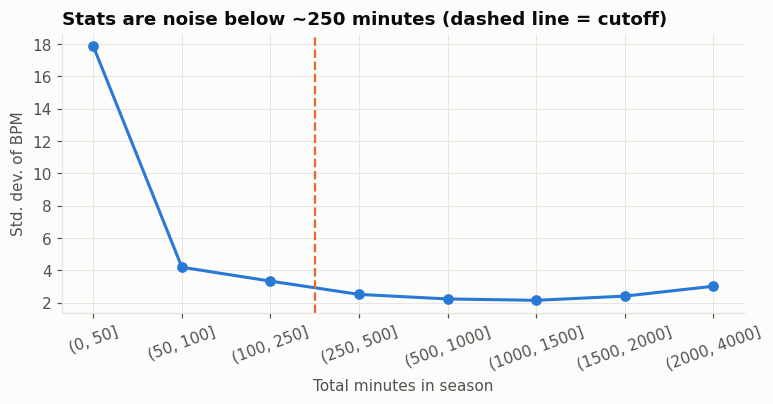

In [2]:
paid = df[df.has_salary].copy()
paid["minutes"] = pd.cut(paid.mp_total, [0, 50, 100, 250, 500, 1000, 1500, 2000, 4000])
sd = paid.groupby("minutes", observed=True).bpm_raw.std()
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(range(len(sd)), sd.values, color=P.BLUE, marker="o", markersize=6)
ax.set_xticks(range(len(sd)), [str(i) for i in sd.index], rotation=20)
ax.axvline(2.5, color=P.ORANGE, linewidth=1.5, linestyle="--")
ax.set_xlabel("Total minutes in season"); ax.set_ylabel("Std. dev. of BPM")
ax.set_title("Stats are noise below ~250 minutes (dashed line = cutoff)")
P.save(fig, "fe_minutes_noise")
plt.show()

**→ Keep player-seasons with ≥ 250 minutes.**

## 3. Rookie contracts

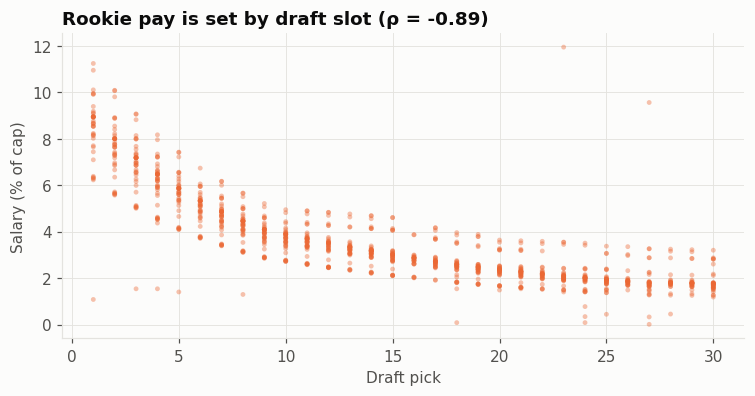

In [3]:
ms = df[df.modeling_sample == 1].copy()
rs = ms[ms.rookie_scale == 1]
rho = rs.pick_overall.corr(rs.salary_pct_cap, method="spearman")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(rs.pick_overall, rs.salary_pct_cap * 100, s=10, alpha=0.4, color=P.ORANGE, edgecolors="none")
ax.set_xlabel("Draft pick"); ax.set_ylabel("Salary (% of cap)")
ax.set_title(f"Rookie pay is set by draft slot (ρ = {rho:.2f})")
P.save(fig, "fe_rookie_scale")
plt.show()

**→ Rookie-scale contracts get their own draft-slot baseline; the main model uses the rest.**

## 4. Modeling sample and split

In [4]:
market = ms[(ms.rookie_scale == 0) & (ms.has_prev_season == 1)].copy()
for c in ["ws", "vorp", "bpm", "mp_total"]:
    market[f"avg2_{c}"] = market[f"avg2_{c}"].fillna(market[f"prev_{c}"])
market["pick_filled"] = market.pick_overall.fillna(61)
market = pd.concat([market, pd.get_dummies(market.pos_group, prefix="pos", dtype=int)], axis=1)
for c in ["prev_pts_per36", "prev_ts_pct"]:
    market[c] = market[c].fillna(market[c].median())

TARGET = "log_salary_pct_cap"
candidates = [
    "prev_pts", "prev_trb", "prev_ast", "prev_mp_per_g", "prev_g", "prev_gs", "prev_mp_total",
    "prev_per", "prev_ts_pct", "prev_usg_pct", "prev_ws", "prev_ws_per_48", "prev_obpm", "prev_dbpm",
    "prev_bpm", "prev_vorp", "prev_availability", "prev_pts_per36", "prev_all_star", "prev_all_nba",
    "avg2_ws", "avg2_vorp", "avg2_bpm", "avg2_mp_total",
    "age", "age_sq", "years_experience", "height_in", "weight", "pick_filled", "undrafted", "first_round",
    "pos_Guard", "pos_Forward", "pos_Center", "shortened_season",
]
market = market.dropna(subset=candidates + [TARGET])
market["split"] = np.select([market.season <= 2023, market.season == 2024], ["train", "valid"], "test")
train, valid = market[market.split == "train"], market[market.split == "valid"]
print(f"{len(market):,} player-seasons, {len(candidates)} candidate features")
market.split.value_counts().reindex(["train", "valid", "test"]).to_frame("rows")

2,833 player-seasons, 36 candidate features


,rows
split,
train,1945
valid,290
test,598


Train 2016-17 → 2022-23 · validate 2023-24 · **test 2024-25 and 2025-26 (untouched)**. Selection uses train only.

## 5. Selection — five methods

In [5]:
spearman = train[candidates].corrwith(train[TARGET], method="spearman").fillna(0)
mi = pd.Series(mutual_info_regression(train[candidates], train[TARGET], random_state=0), index=candidates)

def vif_table(X):
    X = X.loc[:, X.std() > 0]
    Xs = (X - X.mean()) / X.std()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # perfectly collinear columns give VIF = inf
        return pd.Series([variance_inflation_factor(Xs.values, i) for i in range(Xs.shape[1])], index=X.columns)

kept = [c for c in candidates if c != "pos_Forward"]
while True:
    v = vif_table(train[kept]).drop("age")   # keep age; drop its square instead
    if v.max() <= 10:
        break
    kept.remove(v.idxmax())

season_folds = list(GroupKFold(n_splits=5).split(train, groups=train.season))
lasso = make_pipeline(StandardScaler(), LassoCV(cv=season_folds, random_state=0, max_iter=20000))
lasso.fit(train[candidates], train[TARGET])
coefs = pd.Series(lasso[-1].coef_, index=candidates)

gbr = GradientBoostingRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0)
gbr.fit(train[candidates], train[TARGET])
perm = permutation_importance(gbr, valid[candidates], valid[TARGET], n_repeats=15, random_state=0, scoring="r2")
perm_imp = pd.Series(perm.importances_mean, index=candidates)

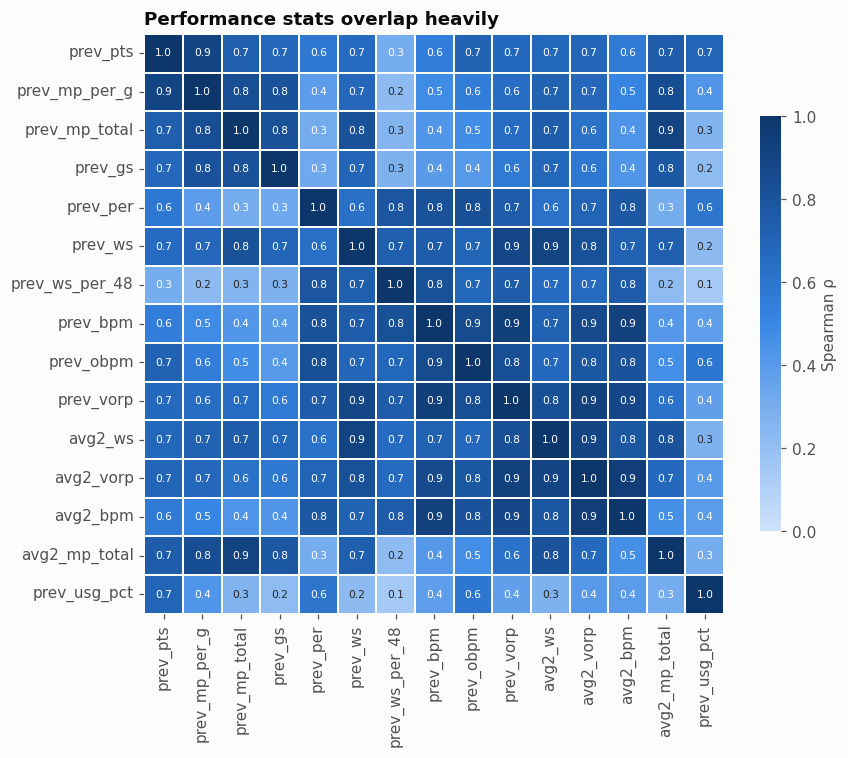

In [6]:
perf = ["prev_pts", "prev_mp_per_g", "prev_mp_total", "prev_gs", "prev_per", "prev_ws", "prev_ws_per_48",
        "prev_bpm", "prev_obpm", "prev_vorp", "avg2_ws", "avg2_vorp", "avg2_bpm", "avg2_mp_total", "prev_usg_pct"]
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(train[perf].corr(method="spearman"), cmap=P.SEQ, vmin=0, vmax=1, square=True, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=1, linecolor=P.SURFACE, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Performance stats overlap heavily"); ax.grid(False)
P.save(fig, "fe_collinearity_heatmap")
plt.show()

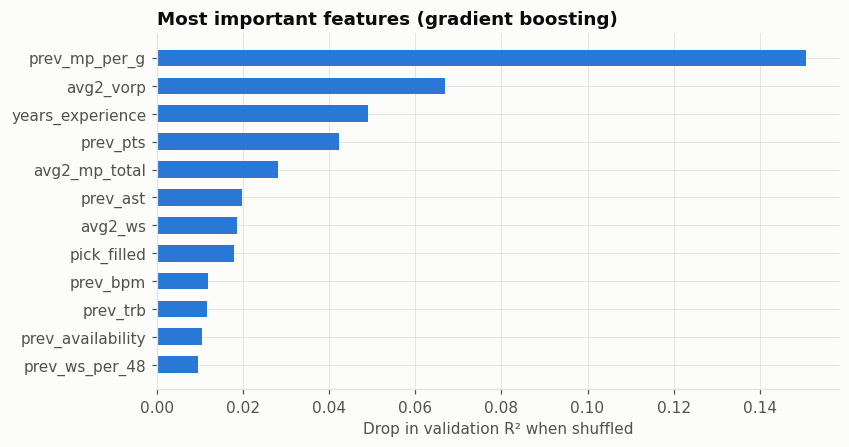

In [7]:
top = perm_imp.sort_values(ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(range(len(top)), top.values, height=0.6, color=P.BLUE)
ax.set_yticks(range(len(top)), top.index)
ax.set_xlabel("Drop in validation R² when shuffled")
ax.set_title("Most important features (gradient boosting)")
P.save(fig, "fe_permutation_importance")
plt.show()

In [8]:
votes = pd.DataFrame({
    "corr": spearman.abs() >= 0.30,
    "MI": spearman.index.isin(mi.nlargest(15).index),
    "VIF": spearman.index.isin(kept),
    "Lasso": coefs != 0,
    "perm": spearman.index.isin(perm_imp.nlargest(15).index),
}, index=candidates)
votes["votes"] = votes.sum(axis=1)

# Keep >= 3 votes, then drop the weaker of any near-duplicate pair (rho > 0.9).
selected = votes[votes.votes >= 3].sort_values("votes", ascending=False, kind="stable").index.tolist()
lagged = [c for c in selected if c.startswith(("prev_", "avg2_"))]
pairs = [(a, b) for i, a in enumerate(lagged) for b in lagged[i + 1:]
         if abs(train[a].corr(train[b], method="spearman")) > 0.9]
for a, b in pairs:
    if a in selected and b in selected:
        selected.remove(a if perm_imp[a] < perm_imp[b] else b)
selected = [c for c in selected if c != "pos_Forward"] + [p for p in ["pos_Guard", "pos_Center"] if p not in selected]
print(f"{len(candidates)} candidates → {len(selected)} selected:\n" + ", ".join(selected))

36 candidates → 21 selected:
prev_trb, prev_mp_per_g, avg2_mp_total, years_experience, pick_filled, prev_ast, prev_gs, prev_usg_pct, prev_ws_per_48, prev_availability, avg2_vorp, prev_per, prev_ws, prev_obpm, prev_all_star, prev_all_nba, weight, undrafted, first_round, pos_Guard, pos_Center


**→ Minutes/role, experience, draft pick and 2-season VORP carry the signal.** Points drop out: once minutes are known they add little (ρ = 0.90).

## 6. Ready to model?

In [9]:
def evaluate(model, feats):
    model.fit(train[feats], train[TARGET])
    pred = model.predict(valid[feats])
    return {"features": len(feats), "R²": r2_score(valid[TARGET], pred),
            "avg error (% of cap)": mean_absolute_error(np.exp(valid[TARGET]) * 100, np.exp(pred) * 100)}

class MeanModel:
    def fit(self, X, y): self.m = y.mean(); return self
    def predict(self, X): return np.full(len(X), self.m)

pd.DataFrame({
    "Predict the mean": evaluate(MeanModel(), selected),
    "Lasso, all features": evaluate(make_pipeline(StandardScaler(), LassoCV(cv=season_folds, max_iter=20000)), candidates),
    "Lasso, selected": evaluate(make_pipeline(StandardScaler(), LassoCV(cv=season_folds, max_iter=20000)), selected),
    "Gradient boosting, selected": evaluate(gbr.__class__(**gbr.get_params()), selected),
}).T.astype({"features": int}).style.format({"R²": "{:.2f}", "avg error (% of cap)": "{:.1f}"})

,features,R²,avg error (% of cap)
Predict the mean,21,-0.00,7.5
"Lasso, all features",36,0.64,3.5
"Lasso, selected",21,0.63,3.6
"Gradient boosting, selected",21,0.67,3.3


**→ Yes.** The selected features explain ~67% of log-salary variance on the 2023-24 season (vs 0% for the mean), and cutting 15 features costs almost nothing.

In [10]:
cols = ["season", "player_id", "player", "final_team", "split", "salary", "salary_cap", "salary_pct_cap", TARGET] + selected
market[cols].to_csv("../data/processed/model_table.csv", index=False)
rs[["season", "player_id", "player", "final_team", "salary", "salary_pct_cap", "pick_overall",
    "years_experience", "vorp", "bpm", "ws"]].to_csv("../data/processed/rookie_scale_table.csv", index=False)
json.dump({"target": TARGET, "features": selected, "candidates": candidates,
           "split": {"train": "2016-2023", "valid": "2024", "test": "2025-2026"}},
          open("../data/processed/selected_features.json", "w"), indent=2)
print("saved model_table.csv, rookie_scale_table.csv, selected_features.json")

saved model_table.csv, rookie_scale_table.csv, selected_features.json


## Next
1. Train and tune models; final test on 2024-25 and 2025-26.
2. Surplus value = actual − predicted pay, per player.
3. Do teams with more surplus value win more?